# 02 · Redes neuronales y retropropagación

**Objetivo:** pasar de una neurona a una red de varias capas, entender *exactamente* cómo la retropropagación calcula los gradientes y entrenar redes desde cero en NumPy.

**Contenido**
1. De las neuronas a las capas (forma matricial)
2. La pasada hacia adelante
3. Funciones de pérdida
4. Retropropagación = la regla de la cadena sobre un grafo computacional
5. Un pequeño motor de autograd (al estilo de micrograd) que cabe en una pantalla
6. Un MLP vectorizado con retropropagación escrita a mano
7. Comprobación de gradientes
8. Entrenamiento: resolver XOR y el problema de las dos lunas
9. Optimizadores: SGD, Momentum, Adam
10. Inicialización y tasa de aprendizaje
11. Comparación con el autograd de PyTorch
12. Ejercicios

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

np.random.seed(0)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. De las neuronas a las capas

Una **capa** son muchas neuronas que leen la misma entrada. Si apilamos sus vectores de pesos como filas de una matriz $W$, podemos calcularlas todas a la vez:

$$ \mathbf{z} = W\mathbf{x} + \mathbf{b}, \qquad \mathbf{a} = f(\mathbf{z}) \qquad\qquad W \in \mathbb{R}^{\text{salida}\times\text{entrada}} $$

Para un **lote** de $N$ muestras guardadas como filas de $X \in \mathbb{R}^{N\times\text{entrada}}$ escribimos $Z = XW^\top + \mathbf{b}$. Un **perceptrón multicapa (MLP)** encadena capas:

```
x ──► [Lineal W1,b1] ──► ReLU ──► [Lineal W2,b2] ──► ReLU ──► [Lineal W3,b3] ──► softmax ──► ŷ
      capa de entrada        capas ocultas (aprenden características)          capa de salida
```

**Teorema de aproximación universal:** una sola capa oculta con suficientes neuronas puede aproximar cualquier función continua en un dominio acotado. En la práctica, las redes *más profundas* necesitan muchas menos neuronas para la misma tarea, porque cada capa reutiliza las características construidas por la anterior.

## 2. La pasada hacia adelante, a mano, sobre XOR

El notebook 01 mostró que una neurona no puede calcular XOR. Dos neuronas ocultas ReLU bastan. Los pesos de abajo se eligieron a mano para demostrar que es *posible*; en la sección 8 se *aprenderán*.

* $h_1 = \text{ReLU}(x_1 + x_2)$ cuenta cuántas entradas están encendidas
* $h_2 = \text{ReLU}(x_1 + x_2 - 1)$ se activa solo cuando ambas lo están
* $\text{salida} = h_1 - 2h_2$ da 0, 1, 1, 0

In [2]:
relu = lambda z: np.maximum(0, z)
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
W1, b1 = np.array([[1.0, 1.0], [1.0, 1.0]]), np.array([0.0, -1.0])
W2, b2 = np.array([[1.0, -2.0]]), np.array([0.0])

H = relu(X_xor @ W1.T + b1)
out = H @ W2.T + b2
for x, h, o in zip(X_xor, H, out):
    print(f"x={x.astype(int)}  oculta={h}  salida={o[0]:.0f}")

x=[0 0]  oculta=[0. 0.]  salida=0
x=[0 1]  oculta=[1. 0.]  salida=1
x=[1 0]  oculta=[1. 0.]  salida=1
x=[1 1]  oculta=[2. 1.]  salida=0


## 3. Funciones de pérdida

La pérdida es un único número que indica cuánto se equivoca la red. El entrenamiento la minimiza.

| Tarea | Capa de salida | Pérdida |
|---|---|---|
| Regresión | lineal | Error cuadrático medio $\frac1N\sum(\hat y - y)^2$ |
| Clasificación binaria | sigmoide | Entropía cruzada binaria |
| Clasificación multiclase | softmax | Entropía cruzada $-\frac1N\sum_i \log \hat p_{i,y_i}$ |
| Modelado del lenguaje (GPT) | softmax sobre el vocabulario | Entropía cruzada sobre el siguiente token |

La entropía cruzada tiene una propiedad preciosa cuando se combina con softmax: $\frac{\partial L}{\partial z_k} = \hat p_k - \mathbb{1}[k=y]$ (la predicción menos el objetivo one-hot), que usaremos más abajo.

## 4. La retropropagación es la regla de la cadena sobre un grafo

Cualquier cálculo puede dibujarse como un **grafo computacional**. Tomemos $L = (wx + b - y)^2$:

```
 w ──┐
     (*)── u ──┐
 x ──┘         (+)── z ──┐
          b ───┘        (-)── e ──(^2)── L
                   y ───┘
```

* **Pasada hacia adelante:** se calculan los valores de izquierda a derecha y se recuerdan.
* **Pasada hacia atrás:** se empieza con $\frac{\partial L}{\partial L}=1$ y se recorre de derecha a izquierda. Cada nodo multiplica el gradiente que le llega por su **derivada local** y lo pasa a sus entradas (regla de la cadena):

$$ \frac{\partial L}{\partial w} = \underbrace{\frac{\partial L}{\partial e}}_{2e}\cdot\underbrace{\frac{\partial e}{\partial z}}_{1}\cdot\underbrace{\frac{\partial z}{\partial u}}_{1}\cdot\underbrace{\frac{\partial u}{\partial w}}_{x} = 2e\,x $$

Si un valor alimenta a varios nodos, los gradientes que llegan por cada camino se **suman**. Eso es todo lo que es la retropropagación (Rumelhart, Hinton y Williams, 1986). Su poder está en la eficiencia: una sola pasada hacia atrás da el gradiente respecto a **todos** los parámetros, con un coste parecido al de una pasada hacia adelante, sean 10 o 10<sup>12</sup>.

## 5. Un pequeño motor de autograd

Abajo hay un motor de diferenciación automática escalar en unas 50 líneas, inspirado en *micrograd* de Andrej Karpathy. Cada `Value` recuerda a sus padres y una clausura `_backward` que aplica el paso local de la regla de la cadena. El `loss.backward()` de PyTorch hace exactamente esto, solo que con tensores y en C++/CUDA.

In [3]:
class Value:
    def __init__(self, data, parents=(), op=""):
        self.data, self.grad = float(data), 0.0
        self._parents, self._op = parents, op
        self._backward = lambda: None

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += out.grad            # d(a+b)/da = 1
            other.grad += out.grad           # d(a+b)/db = 1
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad   # d(ab)/da = b
            other.grad += self.data * out.grad   # d(ab)/db = a
        out._backward = _backward
        return out

    def __pow__(self, k):
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,), "relu")
        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = np.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out

    __radd__ = __add__
    __rmul__ = __mul__
    def __neg__(self):            return self * -1
    def __sub__(self, other):     return self + (-other)
    def __rsub__(self, other):    return (-self) + other

    def backward(self):
        # el orden topológico garantiza que el gradiente de un nodo esté completo antes de propagarse
        order, seen = [], set()
        def build(v):
            if v not in seen:
                seen.add(v)
                for p in v._parents:
                    build(p)
                order.append(v)
        build(self)
        self.grad = 1.0
        for v in reversed(order):
            v._backward()

    def __repr__(self):
        return f"Value(data={self.data:.4f}, grad={self.grad:.4f})"

# El ejemplo de la sección 4
w, x, b, y = Value(2.0), Value(3.0), Value(1.0), Value(4.0)
L = (w * x + b - y) ** 2
L.backward()
e = 2 * 3 + 1 - 4
print("L =", L.data, "| dL/dw =", w.grad, "(esperado 2*e*x =", 2 * e * 3, ") | dL/db =", b.grad, "(esperado 2*e =", 2 * e, ")")

L = 9.0 | dL/dw = 18.0 (esperado 2*e*x = 18 ) | dL/db = 6.0 (esperado 2*e = 6 )


### Entrenar un pequeño MLP con nuestro motor

Neuronas, capas y un MLP construidos íntegramente con objetos `Value`. Es lento (Python puro, un escalar cada vez), pero cada gradiente lo calcula el código de arriba.

parámetros: 37
predicciones: [-1.0, 1.0, 1.0, -1.0] objetivos: [-1.0, 1.0, 1.0, -1.0]


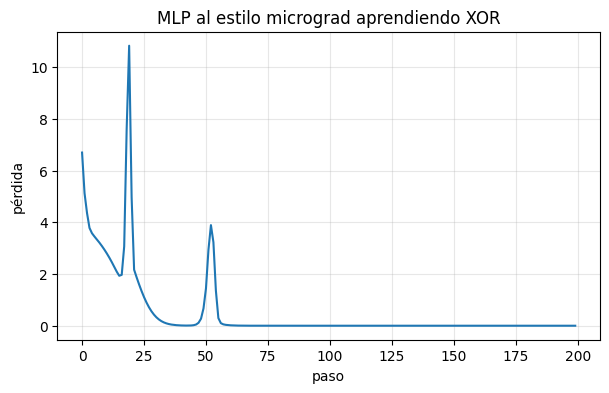

In [4]:
import random
random.seed(1)

class VNeuron:
    def __init__(self, n_in, act=True):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(n_in)]
        self.b = Value(0.0)
        self.act = act
    def __call__(self, x):
        z = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return z.tanh() if self.act else z
    def parameters(self):
        return self.w + [self.b]

class VMLP:
    def __init__(self, sizes):
        self.layers = [[VNeuron(sizes[i], act=(i < len(sizes) - 2)) for _ in range(sizes[i + 1])]
                       for i in range(len(sizes) - 1)]
    def __call__(self, x):
        for layer in self.layers:
            x = [n(x) for n in layer]
        return x[0]
    def parameters(self):
        return [p for layer in self.layers for n in layer for p in n.parameters()]

net = VMLP([2, 4, 4, 1])
targets = [-1.0, 1.0, 1.0, -1.0]                    # XOR con etiquetas en {-1, +1}
losses = []
for step in range(200):
    preds = [net(list(map(Value, x))) for x in X_xor]
    loss = sum(((p - t) ** 2 for p, t in zip(preds, targets)), Value(0.0))
    for p in net.parameters():
        p.grad = 0.0                                 # los gradientes se acumulan, así que se reinician
    loss.backward()
    for p in net.parameters():
        p.data -= 0.05 * p.grad
    losses.append(loss.data)

print("parámetros:", len(net.parameters()))
print("predicciones:", [round(p.data, 3) for p in preds], "objetivos:", targets)
plt.plot(losses); plt.title("MLP al estilo micrograd aprendiendo XOR"); plt.xlabel("paso"); plt.ylabel("pérdida"); plt.show()

## 6. Un MLP vectorizado con retropropagación escrita a mano

Los escalares son geniales para entender y terribles para la velocidad. Las redes reales trabajan con **matrices**. Para una capa lineal $Z = XW^\top + \mathbf{b}$ con gradiente entrante $G = \partial L/\partial Z$:

$$ \frac{\partial L}{\partial W} = G^\top X, \qquad \frac{\partial L}{\partial \mathbf{b}} = \sum_{\text{lote}} G, \qquad \frac{\partial L}{\partial X} = G\,W $$

Comprobar las dimensiones es la forma más fácil de recordarlas: $\partial L/\partial W$ debe tener la forma de $W$.

Para una activación elemento a elemento $A = f(Z)$: $\;\partial L/\partial Z = \partial L/\partial A \odot f'(Z)$.

Cada capa de abajo implementa `forward` (guardando lo que necesitará la pasada hacia atrás) y `backward` (devuelve el gradiente para la capa anterior y guarda los gradientes de sus propios parámetros). Es precisamente el diseño de `nn.Module` + `autograd.Function` en PyTorch.

In [5]:
class Linear:
    def __init__(self, n_in, n_out, init="he"):
        scale = np.sqrt(2.0 / n_in) if init == "he" else (0.01 if init == "small" else 1.0)
        self.W = np.random.randn(n_out, n_in) * scale
        self.b = np.zeros(n_out)
    def forward(self, X):
        self.X = X
        return X @ self.W.T + self.b
    def backward(self, G):
        self.dW = G.T @ self.X
        self.db = G.sum(axis=0)
        return G @ self.W
    def params(self):
        return [(self.W, "dW"), (self.b, "db")]

class ReLU:
    def forward(self, Z):
        self.mask = Z > 0
        return Z * self.mask
    def backward(self, G):
        return G * self.mask
    def params(self):
        return []

class Tanh:
    def forward(self, Z):
        self.A = np.tanh(Z)
        return self.A
    def backward(self, G):
        return G * (1 - self.A ** 2)
    def params(self):
        return []

class SoftmaxCrossEntropy:
    # Fusionadas por estabilidad numérica; el gradiente es (p - onehot) / N
    def forward(self, logits, y):
        z = logits - logits.max(axis=1, keepdims=True)
        self.p = np.exp(z) / np.exp(z).sum(axis=1, keepdims=True)
        self.y = y
        return -np.log(self.p[np.arange(len(y)), y] + 1e-12).mean()
    def backward(self):
        G = self.p.copy()
        G[np.arange(len(self.y)), self.y] -= 1
        return G / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU, init="he"):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCrossEntropy()
    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X
    def loss(self, X, y):
        return self.loss_fn.forward(self.forward(X), y)
    def backward(self):
        G = self.loss_fn.backward()
        for layer in reversed(self.layers):     # el "hacia atrás" de la retropropagación
            G = layer.backward(G)
    def params(self):
        return [(layer, p, g) for layer in self.layers for p, g in layer.params()]
    def predict(self, X):
        return self.forward(X).argmax(axis=1)

net = MLP([2, 8, 2])
print([type(l).__name__ for l in net.layers])

['Linear', 'ReLU', 'Linear']


## 7. Comprobación de gradientes

Es fácil equivocarse sutilmente al escribir la retropropagación a mano. Comparamos cada gradiente analítico con una diferencia finita centrada. Un error relativo por debajo de ~1e-6 significa que la implementación es correcta.

In [6]:
def grad_check(net, X, y, h=1e-5):
    net.loss(X, y); net.backward()
    worst = 0.0
    for layer, P, gname in net.params():
        analytic = getattr(layer, gname)
        numeric = np.zeros_like(P)
        it = np.nditer(P, flags=["multi_index"])
        for _ in it:
            idx = it.multi_index
            old = P[idx]
            P[idx] = old + h; lp = net.loss(X, y)
            P[idx] = old - h; lm = net.loss(X, y)
            P[idx] = old
            numeric[idx] = (lp - lm) / (2 * h)
        rel = np.abs(analytic - numeric).max() / (np.abs(analytic).max() + np.abs(numeric).max() + 1e-12)
        worst = max(worst, rel)
    return worst

Xc, yc = make_moons(20, noise=0.2, random_state=0)
print("error relativo máximo, red ReLU:", f"{grad_check(MLP([2, 5, 4, 2]), Xc, yc):.2e}")
print("error relativo máximo, red Tanh:", f"{grad_check(MLP([2, 5, 4, 2], act=Tanh), Xc, yc):.2e}")

error relativo máximo, red ReLU: 2.16e-10
error relativo máximo, red Tanh: 3.87e-11


## 8. Entrenamiento

El bucle de entrenamiento es el mismo en todos los proyectos de aprendizaje profundo, desde este juguete hasta GPT:

```
para cada época:
    para cada minilote (X, y):
        loss = forward(X, y)          # 1. predecir y medir el error
        backward()                    # 2. gradientes de la pérdida respecto a cada parámetro
        optimizer.step()              # 3. mover los parámetros cuesta abajo
```

### 8a. XOR, aprendido en lugar de diseñado a mano

En teoría bastan dos neuronas ocultas (sección 2), pero el descenso de gradiente desde un inicio aleatorio desafortunado puede atascarse con tan poca capacidad (por ejemplo, si una ReLU muere). Una capa más ancha le da al optimizador muchos más caminos hacia una solución. Este efecto de "sobreparametrizar y después optimizar" es una de las razones por las que las redes grandes se entrenan tan bien.

In [7]:
def sgd_step(net, lr):
    for layer, P, gname in net.params():
        P -= lr * getattr(layer, gname)

y_xor = np.array([0, 1, 1, 0])

def train_xor(hidden, seed, epochs=1000, lr=0.2):
    np.random.seed(seed)
    net = MLP([2, hidden, 2])
    for epoch in range(epochs):
        loss = net.loss(X_xor, y_xor); net.backward(); sgd_step(net, lr)
    return net, loss

net, loss = train_xor(16, seed=0)
print(f"una ejecución, 16 ocultas: pérdida final {loss:.4f}; predicciones {net.predict(X_xor)} frente a objetivos {y_xor}\n")
for hidden in [2, 4, 16]:
    solved = sum((train_xor(hidden, seed)[0].predict(X_xor) == y_xor).all() for seed in range(20))
    print(f"ocultas={hidden:2d}: resolvió XOR en {solved}/20 inicializaciones aleatorias")

una ejecución, 16 ocultas: pérdida final 0.0022; predicciones [0 1 1 0] frente a objetivos [0 1 1 0]



ocultas= 2: resolvió XOR en 3/20 inicializaciones aleatorias


ocultas= 4: resolvió XOR en 10/20 inicializaciones aleatorias


ocultas=16: resolvió XOR en 20/20 inicializaciones aleatorias


### 8b. Dos lunas: una frontera de decisión no lineal

Minilotes, una partición en entrenamiento y prueba, y una gráfica de cómo evoluciona la frontera.

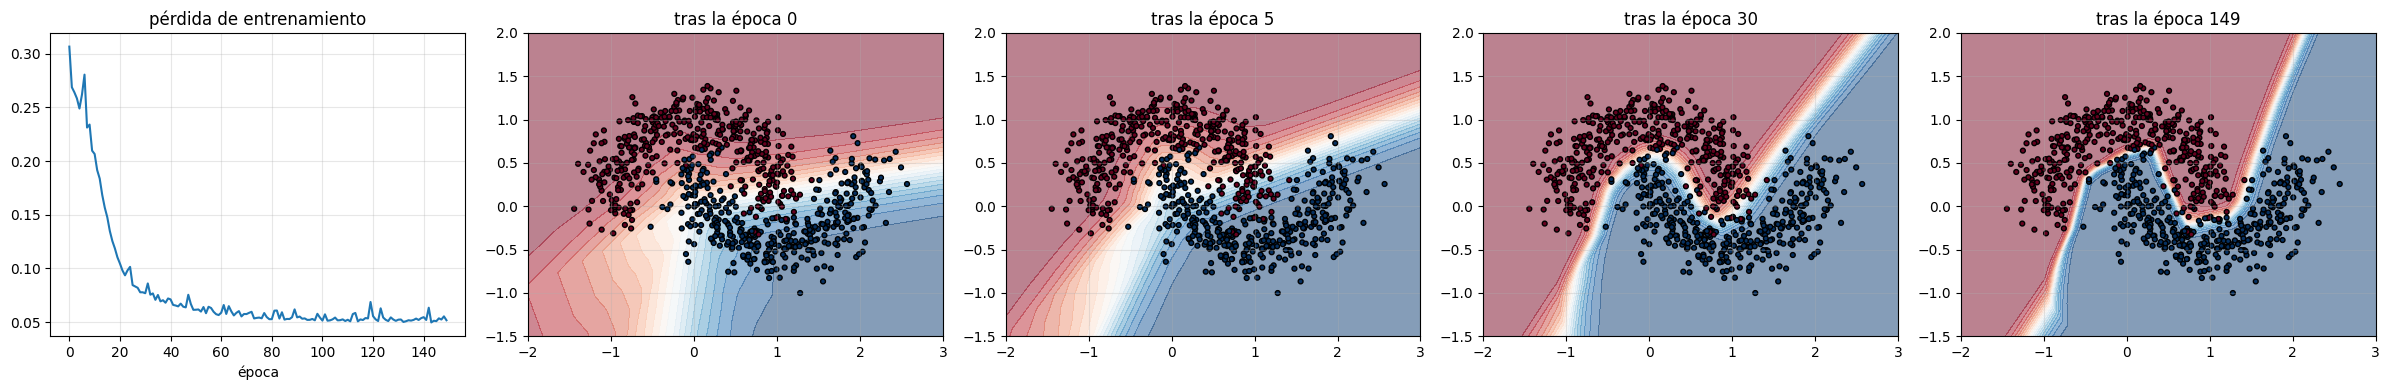

exactitud en entrenamiento 97.9% | en prueba 97.5%


In [8]:
X, y = make_moons(1000, noise=0.2, random_state=42)
idx = np.random.permutation(len(X))
Xtr, ytr, Xte, yte = X[idx[:800]], y[idx[:800]], X[idx[800:]], y[idx[800:]]

def plot_boundary(ax, net, X, y, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 250), np.linspace(-1.5, 2, 250))
    logits = net.forward(np.c_[xx.ravel(), yy.ravel()])
    p = np.exp(logits - logits.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    ax.contourf(xx, yy, p[:, 1].reshape(xx.shape), levels=20, cmap="RdBu", alpha=0.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", edgecolors="k", s=12)
    ax.set_title(title)

def train(net, step_fn, epochs=100, batch=32, verbose=False, snapshots=()):
    hist, snaps = [], {}
    for ep in range(epochs):
        perm = np.random.permutation(len(Xtr))
        for i in range(0, len(Xtr), batch):
            b = perm[i:i + batch]
            net.loss(Xtr[b], ytr[b]); net.backward(); step_fn(net)
        hist.append(net.loss(Xtr, ytr))
        if ep in snapshots:
            snaps[ep] = [(P.copy()) for _, P, _ in net.params()]
    return hist, snaps

np.random.seed(0)
net = MLP([2, 32, 32, 2])
hist, snaps = train(net, lambda n: sgd_step(n, 0.1), epochs=150, snapshots=(0, 5, 30, 149))

fig, axes = plt.subplots(1, 5, figsize=(24, 4))
axes[0].plot(hist); axes[0].set_title("pérdida de entrenamiento"); axes[0].set_xlabel("época")
final = [P.copy() for _, P, _ in net.params()]
for ax, (ep, params) in zip(axes[1:], snaps.items()):
    for (_, P, _), saved in zip(net.params(), params):
        P[...] = saved
    plot_boundary(ax, net, Xtr, ytr, f"tras la época {ep}")
for (_, P, _), saved in zip(net.params(), final):
    P[...] = saved
plt.tight_layout(); plt.show()
print(f"exactitud en entrenamiento {(net.predict(Xtr) == ytr).mean():.1%} | en prueba {(net.predict(Xte) == yte).mean():.1%}")

### ¿Qué aprendió la capa oculta?

Cada neurona de la primera capa dibuja una recta (notebook 01). La segunda capa combina esos semiplanos en regiones curvas. Abajo: la activación de algunas neuronas de la primera capa sobre el espacio de entrada.

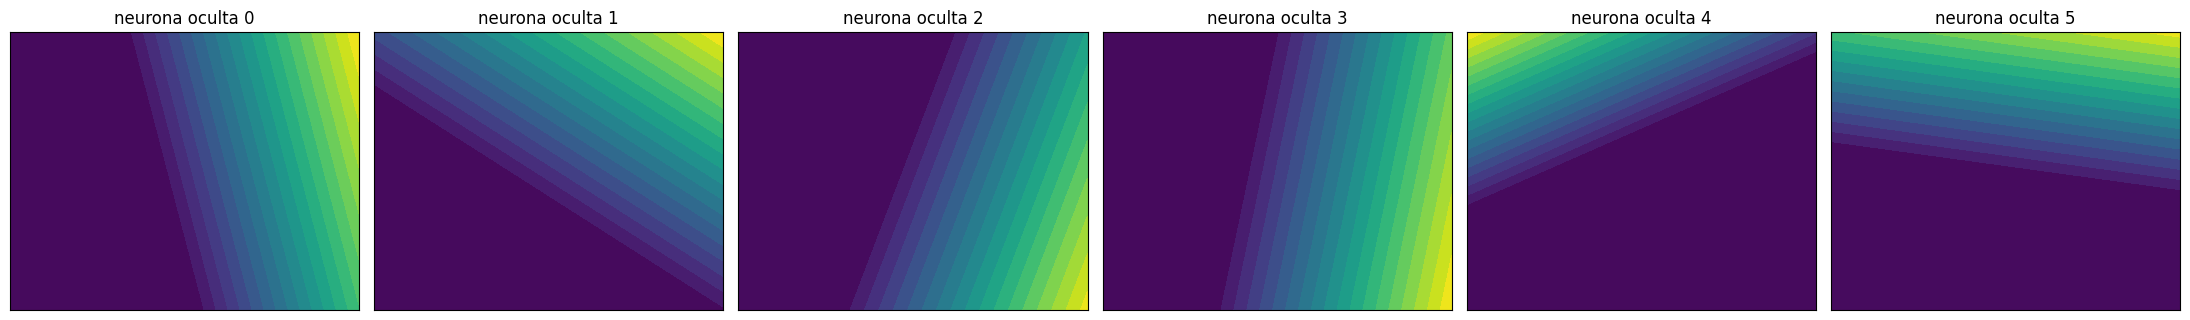

In [9]:
xx, yy = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-1.5, 2, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
H1 = np.maximum(0, grid @ net.layers[0].W.T + net.layers[0].b)
fig, axes = plt.subplots(1, 6, figsize=(22, 3.3))
for k, ax in enumerate(axes):
    ax.contourf(xx, yy, H1[:, k].reshape(xx.shape), levels=20, cmap="viridis")
    ax.set_title(f"neurona oculta {k}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 9. Optimizadores

El SGD simple usa $\theta \leftarrow \theta - \eta\, g$. Dos mejoras impulsan casi todo el entrenamiento moderno:

* **Momentum:** se mantiene una media móvil de los gradientes, $v \leftarrow \beta v + g$, y se avanza en la dirección de $v$. Como una bola pesada, acelera por los valles planos y amortigua los zigzags.
* **Adam** (Kingma y Ba 2014): momentum *más* una escala por parámetro a partir de la media móvil de los gradientes al cuadrado, de modo que cada parámetro tiene su propia tasa de aprendizaje efectiva. Los modelos tipo GPT usan **AdamW** (Adam + decaimiento de pesos desacoplado).

$$ m \leftarrow \beta_1 m + (1-\beta_1) g,\quad v \leftarrow \beta_2 v + (1-\beta_2) g^2,\quad \theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon} $$

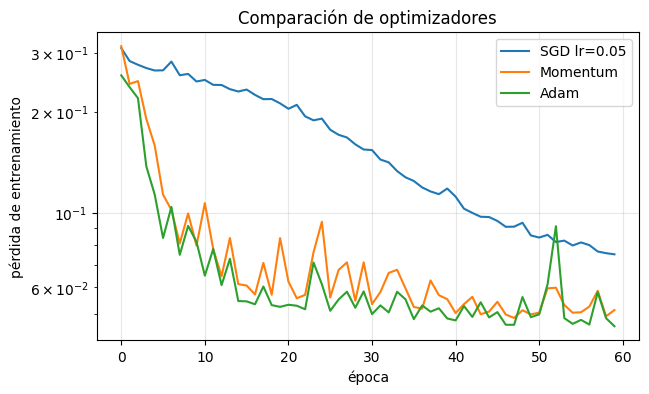

In [10]:
class Momentum:
    def __init__(self, lr=0.05, beta=0.9):
        self.lr, self.beta, self.v = lr, beta, {}
    def __call__(self, net):
        for i, (layer, P, g) in enumerate(net.params()):
            self.v[i] = self.beta * self.v.get(i, 0) + getattr(layer, g)
            P -= self.lr * self.v[i]

class Adam:
    def __init__(self, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t, self.m, self.v = lr, b1, b2, eps, 0, {}, {}
    def __call__(self, net):
        self.t += 1
        for i, (layer, P, g) in enumerate(net.params()):
            G = getattr(layer, g)
            self.m[i] = self.b1 * self.m.get(i, 0) + (1 - self.b1) * G
            self.v[i] = self.b2 * self.v.get(i, 0) + (1 - self.b2) * G ** 2
            m_hat = self.m[i] / (1 - self.b1 ** self.t)      # corrección del sesgo en los primeros pasos
            v_hat = self.v[i] / (1 - self.b2 ** self.t)
            P -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

results = {}
for name, opt in [("SGD lr=0.05", lambda n: sgd_step(n, 0.05)), ("Momentum", Momentum()), ("Adam", Adam())]:
    np.random.seed(0)
    results[name], _ = train(MLP([2, 32, 32, 2]), opt, epochs=60)
for name, h in results.items():
    plt.plot(h, label=name)
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento"); plt.legend(); plt.title("Comparación de optimizadores"); plt.show()

## 10. Inicialización y tasa de aprendizaje

**Inicialización.** Si los pesos son demasiado pequeños, las activaciones se encogen capa tras capa hasta que la señal (y el gradiente) desaparece. Si son demasiado grandes, explotan. La **inicialización de He** ($\mathcal{N}(0, 2/n_{in})$) mantiene aproximadamente constante la varianza de las activaciones ReLU a lo largo de la profundidad. La gráfica muestra la dispersión de las activaciones en una red de 10 capas para tres opciones.

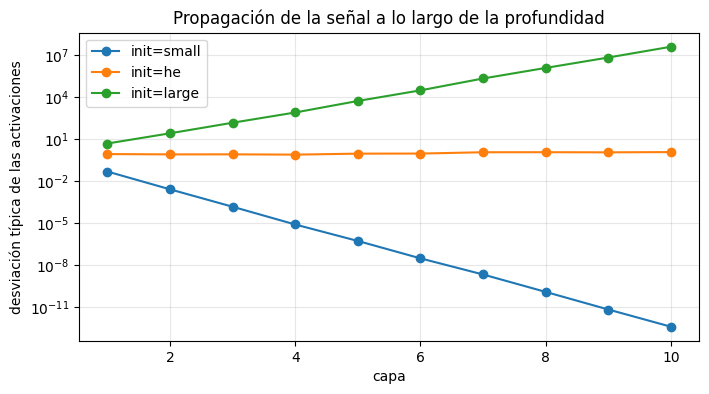

In [11]:
Xs = np.random.randn(500, 64)
fig, ax = plt.subplots(figsize=(8, 4))
for init in ["small", "he", "large"]:
    np.random.seed(0)
    deep = MLP([64] * 11 + [2], init=init)
    A, stds = Xs, []
    for layer in deep.layers[:-1]:
        A = layer.forward(A)
        if isinstance(layer, ReLU):
            stds.append(A.std())
    ax.semilogy(range(1, len(stds) + 1), stds, marker="o", label=f"init={init}")
ax.set_xlabel("capa"); ax.set_ylabel("desviación típica de las activaciones"); ax.legend(); ax.set_title("Propagación de la señal a lo largo de la profundidad")
plt.show()

La **tasa de aprendizaje** es el hiperparámetro más importante. Demasiado pequeña: lento. Demasiado grande: la pérdida oscila o diverge.

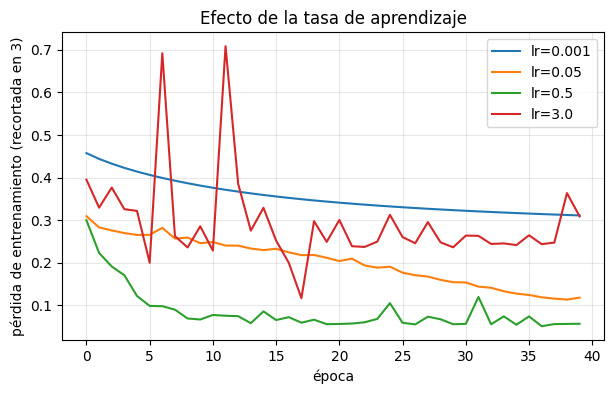

In [12]:
for lr in [0.001, 0.05, 0.5, 3.0]:
    np.random.seed(0)
    h, _ = train(MLP([2, 32, 32, 2]), lambda n, lr=lr: sgd_step(n, lr), epochs=40)
    plt.plot(np.clip(h, 0, 3), label=f"lr={lr}")
plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento (recortada en 3)"); plt.legend(); plt.title("Efecto de la tasa de aprendizaje"); plt.show()

## 11. Comparación con el autograd de PyTorch

Copiamos los pesos de nuestra red de NumPy a PyTorch, procesamos el mismo lote y comparamos los gradientes. Coinciden hasta la precisión de coma flotante: `loss.backward()` es el algoritmo que acabamos de escribir.

In [13]:
import torch
np.random.seed(0)
ours = MLP([2, 16, 16, 2])
Xb, yb = Xtr[:64], ytr[:64]
ours.loss(Xb, yb); ours.backward()

lin = [l for l in ours.layers if isinstance(l, Linear)]
tparams = [(torch.tensor(l.W, requires_grad=True), torch.tensor(l.b, requires_grad=True)) for l in lin]
h = torch.tensor(Xb)
for i, (W, b) in enumerate(tparams):
    h = h @ W.T + b
    if i < len(tparams) - 1:
        h = torch.relu(h)
loss = torch.nn.functional.cross_entropy(h, torch.tensor(yb))
loss.backward()
for i, (l, (W, b)) in enumerate(zip(lin, tparams)):
    print(f"capa {i}: máx |dW nuestro - dW torch| = {np.abs(l.dW - W.grad.numpy()).max():.2e}, "
          f"máx |diferencia db| = {np.abs(l.db - b.grad.numpy()).max():.2e}")

capa 0: máx |dW nuestro - dW torch| = 2.78e-17, máx |diferencia db| = 2.78e-17
capa 1: máx |dW nuestro - dW torch| = 1.11e-16, máx |diferencia db| = 2.78e-17
capa 2: máx |dW nuestro - dW torch| = 1.11e-16, máx |diferencia db| = 1.11e-16


## Ideas clave

* Una red son capas de neuronas; una capa es una multiplicación de matrices más una no linealidad.
* La **retropropagación** aplica la regla de la cadena hacia atrás a través del grafo computacional; una sola pasada hacia atrás da todos los gradientes.
* Gradientes de una capa lineal: $dW = G^\top X$, $db=\sum G$, $dX = GW$. Las activaciones multiplican por $f'(z)$ elemento a elemento.
* **Comprueba siempre los gradientes** de una pasada hacia atrás escrita a mano.
* **Adam** + **inicialización de He** + una **tasa de aprendizaje** sensata hacen que el entrenamiento sea fiable.
* PyTorch automatiza exactamente esto, y es lo que usamos de los notebooks 03 al 09.

## Ejercicios

1. Añade una clase de capa `Sigmoid` y entrena con ella la red de las dos lunas. Compárala con ReLU y Tanh.
2. Añade **decaimiento de pesos L2** a `sgd_step` ($P \leftarrow P - \eta(\nabla + \lambda P)$). ¿Cómo cambia la frontera de decisión con un $\lambda$ grande?
3. Añade los métodos `__truediv__` y `exp` a `Value` e implementa softmax con el motor escalar.
4. Entrena con `sklearn.datasets.make_circles`. ¿Cuál es la capa oculta más pequeña que lo resuelve?
5. Implementa **dropout** como una capa (máscara aleatoria durante el entrenamiento, identidad en la prueba).